# **Libraries**
---
The libraries used throughout the workflow are imported: utilities, visualization, data manipulation, synthetic dataset generation, decision tree modeling, hyperparameter search with cross-validation, and the evaluation metric (accuracy).

In [1]:
# Utils
# ==============================================================================
import warnings

# Plot
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Data
# ==============================================================================
import pandas as pd
import numpy as np
from sklearn.datasets import make_classification

# Model
# ==============================================================================
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Metrics
# ==============================================================================
from sklearn.metrics import accuracy_score

# **Info**
---

**@By**: Steven Bernal

**@Nickname**: Kaiziferr

**@Git**: https://github.com/Kaiziferr

# **Config**
---
The seaborn `darkgrid` style is applied to the plots, warnings are disabled, a color palette is defined from the tab10 palette, and the random seed is set to `12354`. The seed is used in data generation, in the data split, and in the base model, so the results can be reproduced.

In [2]:
sns.set(style="darkgrid")
warnings.simplefilter("ignore")
paleta = sns.color_palette("tab10").as_hex()
random_seed = 12354

# **Context**
---

A synthetic dataset was chosen for this classification problem because it provides a controlled and educational environment, specifically designed to explain how the complexity of a decision tree is controlled through the **ccp_alpha** hyperparameter.

Working with real-world datasets usually requires a significant amount of effort in preprocessing tasks such as data cleaning, handling missing values, correcting inconsistencies, and transforming variables. While these steps are essential in any data science workflow, they are outside the scope of this analysis.

In this analysis, ccp_alpha is treated as a **pre-pruning** hyperparameter. Its value is defined before training and selected through Grid Search, in the same way as max_depth or min_samples_leaf. Three ways of building the candidate grid are compared: a logarithmic range generated with np.logspace(), a set of manually defined values, and the values computed with cost_complexity_pruning_path.

The internal mechanism requires clarification. **Cost-Complexity Pruning** comes from **post-pruning**. In Scikit-Learn, the tree is fully grown, and then the branches whose contribution does not offset the penalty defined by ccp_alpha are removed. For this reason, cost_complexity_pruning_path, which belongs to that approach, is used here as a source of candidates for the hyperparameter search.

# **Goals**
---

- Apply ccp_alpha as a pre-pruning hyperparameter in a decision tree for a classification problem with synthetic data.
- Compare three strategies for defining the ccp_alpha candidates: a logarithmic range, manual values, and the Cost-Complexity Pruning Path.
- Analyze how each selected value affects the impurity, number of nodes, depth, and accuracy of the tree.

# **Data**
---

- The dataset is generated with `1,000` samples and 10 features. Of these, 6 features are informative and 2 are redundant. No duplicated features are included.
- The task is a binary classification problem with two classes. Each class is distributed into two clusters within the feature space.
- A label noise rate of 0.08 is introduced, meaning that 8% of the labels are randomly flipped. The class separation is set to 0.8, and the classes are balanced.
- A random seed is used to ensure the reproducibility of the dataset.

In [3]:
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=2,
    weights=[0.5, 0.5],
    flip_y=0.08,
    class_sep=0.8,
    random_state=random_seed
)

The feature matrix is converted into a pandas DataFrame, and each column is named A0, A1, …, A9. This makes it easier to identify the features in later stages.

In [4]:
X = pd.DataFrame(X, columns=[f'A{i}'for i in range(X.shape[1])])

# **Data Split**
---

The dataset is split into training and test sets using a random partition. The test set receives 20% of the samples, and the remaining 80% is used for training. This results in 800 training samples and 200 test samples.

The split preserves the correspondence between the input features and their labels. A random seed is used to ensure the reproducibility of the partition.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=random_seed
)

# **Model**
---

A base Decision Tree is defined with the fixed seed, and its **Cost-Complexity Pruning Path** is computed with cost_complexity_pruning_path. Internally, Scikit-Learn fits a full tree (ccp_alpha=0) on the training data and goes through the sequence of successive pruning steps. The method returns two outputs:

- **ccp_alphas:** the effective values of the complexity parameter at which the tree structure changes.
- **impurities:** the total impurity of the terminal nodes (leaves) after each pruning step.

Together, these values describe the complete pruning path. Each ccp_alpha represents a candidate subtree with a different level of complexity. Any ccp_alpha value located between two consecutive values of the path produces the same tree as the smaller of the two. This information is the basis for building the third search grid.

The model object is not fitted by this call. It is reused later as the base estimator of the Grid Search.

In [6]:
model = DecisionTreeClassifier(random_state=random_seed)
path = model.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

The first parameter grid generates the candidate values automatically using np.logspace(). This creates `10 values` logarithmically spaced between 10⁻⁵ and 10⁻¹, providing a broad search across several orders of magnitude. Logarithmic spacing is useful when the optimal value is unknown and may lie anywhere within a wide numerical range. Its limitation is that the candidates do not depend on the structure of the tree, so some of them may produce the same subtree or fall outside the range where the tree changes.

In [7]:
dic_params_opt_0 = {
    "ccp_alpha": np.logspace(-5, -1, 10)
}

The second parameter grid defines the candidate values manually. Instead of values evenly spaced on a logarithmic scale, it includes `9 specific` ccp_alpha values between 0.00001 and 0.1 that are commonly tested in practice. This approach provides greater control over the search space and allows the evaluation to focus on values considered relevant based on prior knowledge or experimentation. Like the logarithmic grid, it does not take the structure of the trained tree into account.

In [8]:
dic_params_opt_1 = {
    "ccp_alpha": [
        0.00001,
        0.00005,
        0.0001,
        0.0005,
        0.001,
        0.005,
        0.01,
        0.05,
        0.1
    ]
}

The third parameter grid uses the values returned by the Cost-Complexity Pruning Path (cost_complexity_pruning_path). Since these ccp_alpha values are computed directly from the structure of the trained decision tree, every candidate represents a valid pruning point where the tree changes. The last value is excluded (ccp_alphas[:-1]) because it corresponds to pruning the entire tree and leaving only the root node, which is not useful for predictive modeling.

In [9]:
dic_params_opt_2 = {
    "ccp_alpha": ccp_alphas[:-1]
}

- A Grid Search (GridSearchCV) is performed independently for each of the three parameter grids. For every search space, 10-fold cross-validation (cv=10) is used to identify the ccp_alpha value that maximizes the mean validation accuracy.
- With refit=True, the best estimator is retrained on the full training set and evaluated on both the training and test sets. For each strategy, the output reports the depth and number of nodes of the tree, the best cross-validation score with four decimals, the selected ccp_alpha, and the training and test accuracy.
- Finally, the best ccp_alpha from each grid is stored in the best_params dictionary under the keys opt_0 (logarithmic range), opt_1 (manual values), and opt_2 (pruning path). These keys are labeled in the plots as `alpha v0`, `alpha v1`, and `alpha v2`.

In [10]:
best_params = {}


for e, params in enumerate([dic_params_opt_0, dic_params_opt_1, dic_params_opt_2]):
  model_classifier_prepruning = GridSearchCV(
    estimator= model,
    param_grid=params,
    scoring='accuracy',
    cv=10,
    refit=True,
    return_train_score = True
  )
  model_classifier_prepruning.fit(X_train, y_train)
  best_params[f'opt_{e}'] = model_classifier_prepruning.best_params_
  model_classifier_prepruning_best = model_classifier_prepruning.best_estimator_
  print(f"Tree depth: {model_classifier_prepruning_best.get_depth()}")
  print(f"Number of nodes: {model_classifier_prepruning_best.tree_.node_count}")
  print(f'The best score: {model_classifier_prepruning.best_score_:.4f}')
  print(f'The best params: {model_classifier_prepruning.best_params_}')
  y_predict_prepruning_v1_test = model_classifier_prepruning_best.predict(X_test)
  y_predict_prepruning_v1_train = model_classifier_prepruning_best.predict(X_train)
  print(f'Prediction Data Train: {accuracy_score(y_train, y_predict_prepruning_v1_train)}')
  print(f'Prediction Data Test: {accuracy_score(y_test, y_predict_prepruning_v1_test)}')
  print("\n")


Tree depth: 13
Number of nodes: 135
The best score: 0.8262
The best params: {'ccp_alpha': np.float64(0.001668100537200059)}
Prediction Data Train: 0.98
Prediction Data Test: 0.755


Tree depth: 15
Number of nodes: 189
The best score: 0.8250
The best params: {'ccp_alpha': 1e-05}
Prediction Data Train: 1.0
Prediction Data Test: 0.755


Tree depth: 10
Number of nodes: 63
The best score: 0.8300
The best params: {'ccp_alpha': np.float64(0.003705882352941177)}
Prediction Data Train: 0.925
Prediction Data Test: 0.75




The results are presented in the same order as the parameter grids:

| Strategy | Selected ccp_alpha | Depth | Nodes | CV | Training accuracy | Test accuracy | Gap |
|---|---|---|---|---|---|---|---|
| Logarithmic range (alpha v0) | 0.001668 | 13 | 135 | 0.8262 | 0.980 | 0.755 | 22.5 pts |
| Manual values (alpha v1) | 0.00001 | 15 | 189 | 0.8250 | 1.000 | 0.755 | 24.5 pts |
| Pruning path (alpha v2) | 0.003706 | 10 | 63 | 0.8300 | 0.925 | 0.750 | 17.5 pts |

- **Predictive performance:** the three models obtained practically the same test accuracy. The difference between 0.755 and 0.750 corresponds to `a single sample` out of the 200 in the test set. The cross-validation scores are also very close. The difference between the highest (0.8300) and the lowest (0.8250) is 0.5 percentage points. Based on these results, it cannot be concluded that one strategy generalizes better than another.
- **Complexity:** the difference lies in the size of the tree. The pruning path selected the simplest tree, with a depth of `10` and `63 nodes`, compared with a depth of 13 and 135 nodes for the logarithmic range, and a depth of 15 and 189 nodes for the manual values.
- **Manual values:** the selected value is the smallest in the grid (0.00001), with a training accuracy of 1.0, a depth of 15, and 189 nodes. As shown later in the plots, this is the structure of the unpruned tree, so this ccp_alpha value did not remove any branches. Candidates smaller than the first effective alpha of the path produce the same tree and the same score. When there is a tie, GridSearchCV selects the first candidate in the list.
- **Overfitting:** the three configurations show a considerable gap between training and test accuracy. The smallest gap corresponds to the pruning path (`17.5 points`), which is consistent with a more heavily pruned tree. Even so, the 8% label noise limits the accuracy that can be achieved on the test set.

Overall, different ccp_alpha values produced trees of very different sizes without relevant changes in test accuracy. The pruning path identified a simpler tree that generalizes almost as well as the more complex alternatives, which makes it preferable when model interpretability is important.

## **Pruning Path Analysis**
---
To analyze how Cost-Complexity Pruning changes the structure of the tree, a separate model is trained for each ccp_alpha value in the path, and all the trees are stored in a list (clfs). This collection is used in the following plots to compare how the number of nodes and the depth change as the pruning strength increases.

At the end, the number of nodes of the last tree in the list is printed. This tree corresponds to the largest ccp_alpha in the path.

In [11]:
clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=random_seed, ccp_alpha=ccp_alpha)
    clf.fit(X_train, y_train)
    clfs.append(clf)
print(
    "Number of nodes in the last tree is: {} with ccp_alpha: {}".format(
        clfs[-1].tree_.node_count, ccp_alphas[-1]
    )
)

Number of nodes in the last tree is: 1 with ccp_alpha: 0.07394942052260756


The last tree has `1 node` with ccp_alpha ≈ 0.0739. In other words, with the largest value of the path, the tree is reduced to the root node and predicts the same class for all observations. This result confirms why this value was excluded from the third search grid and why it is also excluded from the following plots.

These trees are trained with the same seed (random_seed) as the base model and the Grid Search, so their structures are comparable with the trees selected in the previous section.

The first plot shows how the total impurity of the leaves evolves as the effective ccp_alpha increases, using the path values without the last point.

- **X-axis:** effective ccp_alpha.
- **Y-axis:** total leaf impurity of the pruned tree, computed on the training set.
- **Vertical lines:** ccp_alpha selected by each strategy: logarithmic range (red, alpha v0), manual values (green, alpha v1), and pruning path (blue, alpha v2).

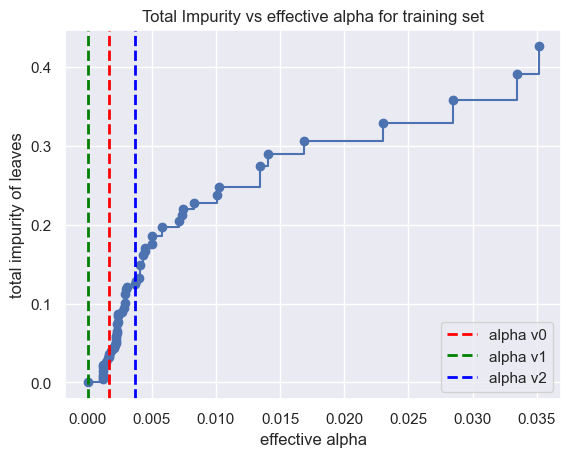

In [12]:
fig, ax = plt.subplots()
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.axvline(best_params['opt_0']['ccp_alpha'], color='red', linestyle='--', linewidth=2, label='alpha v0')
ax.axvline(best_params['opt_1']['ccp_alpha'], color='green', linestyle='--', linewidth=2, label='alpha v1')
ax.axvline(best_params['opt_2']['ccp_alpha'], color='blue', linestyle='--', linewidth=2, label='alpha v2')
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")
plt.legend()
plt.show()

- **Starting point:** with ccp_alpha=0, the total impurity is `0`. The unpruned tree has pure leaves, which is consistent with the training accuracy of 1.0 observed for the manual grid.
- **First section:** most of the points in the path are concentrated between 0 and approximately 0.005. Each pruning step removes small branches and increases the impurity only slightly, but since the steps are very close together, the curve rises quickly. The impurity goes from 0 to approximately 0.17 in that interval.
- **Final section:** from 0.01 onward, the points are farther apart, and each step produces larger jumps, reaching approximately 0.43 at ccp_alpha ≈ 0.035. In this region, branches close to the root are removed, and the remaining leaves represent larger and more heterogeneous regions of the feature space.
- **Selected values:** the alpha v1 value (0.00001) is located at the beginning of the curve, with an impurity of 0, which confirms that no pruning was applied. The alpha v0 value (≈ 0.0017) is located slightly further along, with an impurity of approximately 0.04. The alpha v2 value (≈ 0.0037) is further along the path, with an impurity of approximately 0.12, and corresponds to the strongest pruning of the three.

The plot shows the role of ccp_alpha as a complexity control parameter. As its value increases, pruning becomes stronger, the tree becomes simpler, and a gradual increase in leaf impurity is accepted. The three selected values are located in the first section of the path, where the impurity is still low.

The second plot shows how the number of nodes changes throughout the pruning process. As ccp_alpha increases, branches are progressively removed, producing smaller trees. The vertical lines and colors are the same as in the previous plot.

- **X-axis:** effective ccp_alpha.
- **Y-axis:** total number of nodes in the tree (internal nodes and leaves).

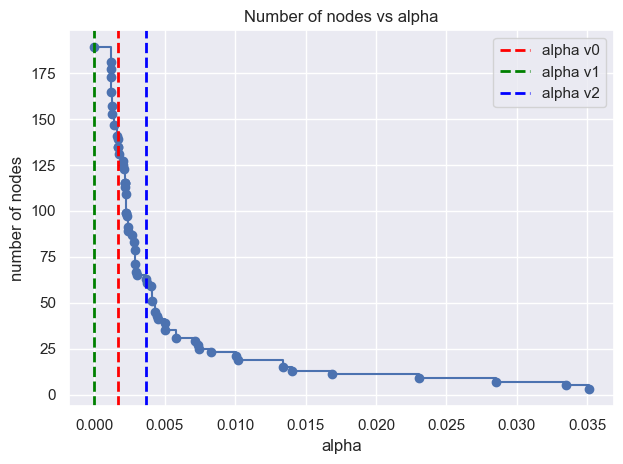

In [13]:
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]
fig, ax = plt.subplots()
ax.plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax.axvline(best_params['opt_0']['ccp_alpha'], color='red', linestyle='--', linewidth=2, label='alpha v0')
ax.axvline(best_params['opt_1']['ccp_alpha'], color='green', linestyle='--', linewidth=2, label='alpha v1')
ax.axvline(best_params['opt_2']['ccp_alpha'], color='blue', linestyle='--', linewidth=2, label='alpha v2')
ax.set_xlabel("alpha")
ax.set_ylabel("number of nodes")
ax.set_title("Number of nodes vs alpha")
plt.legend()
fig.tight_layout()
plt.show()

- **Unpruned tree:** with ccp_alpha=0, the tree has `189 nodes`.
- **Initial reduction:** the number of nodes drops quickly in the first section. Before ccp_alpha ≈ 0.005, the tree goes from 189 to fewer than 50 nodes. Most of the simplification occurs with very small ccp_alpha values.
- **Final section:** from 0.01 onward, the curve flattens, and the tree goes from approximately 20 nodes to only 3 at ccp_alpha ≈ 0.035.
- **Selected values:** the alpha v1 value keeps the full tree with 189 nodes. The alpha v0 value reduces it to 135 nodes, 28.6% fewer. The alpha v2 value reduces it to 63 nodes, exactly one third of the original tree.

This plot highlights one of the main advantages of Cost-Complexity Pruning: small increases in ccp_alpha can greatly reduce the size of the tree. When compared with the search results, the alpha v2 tree has one third of the nodes of the full tree and obtained practically the same test accuracy (0.750 compared with 0.755).

The third plot presents the relationship between the maximum depth of the tree and ccp_alpha. It shows how stronger pruning simplifies the hierarchical structure of the tree and allows the depth associated with each selected ccp_alpha to be compared.

- **X-axis:** effective ccp_alpha.
- **Y-axis:** maximum depth of the tree, that is, the length of the longest path from the root to a leaf.
- **Vertical lines:** ccp_alpha selected by each strategy, with the same colors as in the previous plots: logarithmic range (red, alpha v0), manual values (green, alpha v1), and pruning path (blue, alpha v2).

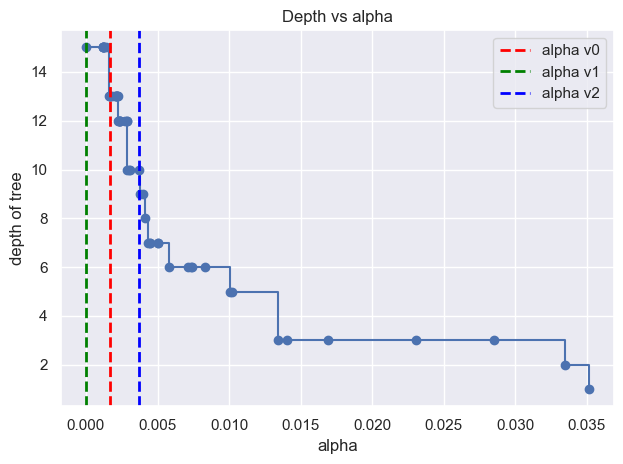

In [14]:
fig, ax = plt.subplots()
ax.plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax.set_xlabel("alpha")
ax.set_ylabel("depth of tree")
ax.set_title("Depth vs alpha")
ax.axvline(best_params['opt_0']['ccp_alpha'], color='red', linestyle='--', linewidth=2, label='alpha v0')
ax.axvline(best_params['opt_1']['ccp_alpha'], color='green', linestyle='--', linewidth=2, label='alpha v1')
ax.axvline(best_params['opt_2']['ccp_alpha'], color='blue', linestyle='--', linewidth=2, label='alpha v2')
plt.legend()
fig.tight_layout()
plt.show()

- **General behavior:** the depth decreases as ccp_alpha increases, in wider steps than the number of nodes. For example, it remains at 3 between ccp_alpha ≈ 0.013 and ≈ 0.033 and then drops to 2 and 1. Several pruning operations may occur before the longest path between the root and a leaf is shortened.
- **Selected values:** the alpha v1 value keeps the maximum depth of the tree, `15`. The alpha v0 value reduces it to 13, and the alpha v2 value reduces it to 10. These values match the depths printed in the Grid Search.
- **Comparison with the number of nodes:** the number of nodes decreases faster than the depth. Between the full tree and alpha v2, the number of nodes decreases by 66.7% (from 189 to 63), while the depth decreases by 33.3% (from 15 to 10). This occurs because many pruning operations remove subtrees from the lower levels without immediately affecting the longest path in the tree.

In practical terms, alpha v2 produces a tree with five fewer levels than the full tree. A shallower tree generates shorter decision rules that are easier to interpret.

## **Caution When Defining the ccp_alpha Candidate Range**
---
The last plot repeats the depth versus ccp_alpha curve, but the vertical lines mark four of the ten candidates from the logarithmic grid (dic_params_opt_0) instead of the selected values:

- Position 0: 0.00001, the smallest value in the grid.
- Position 5: ≈ 0.0017, the value selected by the search (alpha v0).
- Position 8: ≈ 0.0359.
- Position 9: 0.1, the largest value in the grid.

The objective is to check whether candidates defined without reference to the structure of the tree fall within the range of the pruning path, which is where ccp_alpha actually modifies the tree. Each line has its own color, and the legend shows the position of the candidate in the grid and its value. The red line corresponds to the value selected by the search (alpha v0), with the same color used in the previous plots.

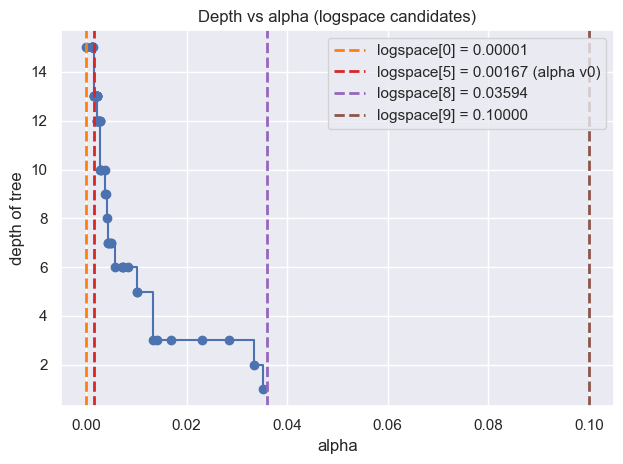

In [15]:
logspace_values = dic_params_opt_0['ccp_alpha']
logspace_idx = [0, 5, 8, 9]
logspace_colors = [paleta[1], paleta[3], paleta[4], paleta[5]]

fig, ax = plt.subplots()
ax.plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax.set_xlabel("alpha")
ax.set_ylabel("depth of tree")
ax.set_title("Depth vs alpha (logspace candidates)")
for idx, color in zip(logspace_idx, logspace_colors):
    label = f'logspace[{idx}] = {logspace_values[idx]:.5f}'
    if idx == 5:
        label += ' (alpha v0)'
    ax.axvline(logspace_values[idx], color=color, linestyle='--', linewidth=2, label=label)
plt.legend()
fig.tight_layout()
plt.show()

- **Range overflow:** the last two lines fall outside the plotted pruning path, whose last point is at ≈ 0.0351. The purple line (≈ 0.0359) produces a tree with a depth of 1, that is, a single split. The brown line (0.1) exceeds even the largest value of the path (≈ 0.0739), which, according to the previous output, reduces the tree to the root node. These candidates do not evaluate an intermediate level of pruning, only trivial trees. In addition, the X-axis has to extend to 0.1 to show them, and the entire pruning path is compressed into the left part of the plot.
- **Concentration at a single point:** the orange (0.00001) and red (≈ 0.0017) lines appear almost overlapping near the origin. According to the first plot, the first effective alpha of the path after 0 is approximately 0.0012, and the first five values of the logarithmic grid (from 0.00001 to ≈ 0.0006) are smaller. All of them produce the same unpruned tree, with a depth of 15. The manual grid has the same problem with its first five values (from 0.00001 to 0.001), which explains why the manual search selected a value that did not apply any pruning.
- **Useful range:** between these two extremes, only the intermediate values of the grid fall within the region where the structure of the tree changes.

This plot highlights the caution required when ccp_alpha candidates are defined arbitrarily or with np.logspace(). If the range overflows, the candidates produce trivial trees. If it is concentrated in a region where the tree does not change, several candidates evaluate the same model. In both cases, the search spends evaluations without exploring different levels of pruning. Before the range is defined, its limits should be checked against cost_complexity_pruning_path. The lower limit should be close to the first nonzero effective alpha, and the upper limit should not reach the last value of the path, which leaves only the root node.

# **Conclusions**
---
- The ccp_alpha hyperparameter makes it possible to control the complexity of the tree with a single value defined before training. In this analysis, it was treated as a pre-pruning hyperparameter, although Scikit-Learn applies pruning after the full tree is grown.
- The three strategies obtained practically the same test accuracy (0.755, 0.755, and 0.750) and cross-validation accuracy (0.8262, 0.8250, and 0.8300), but trees of very different sizes. The grid based on cost_complexity_pruning_path selected the simplest tree, with a depth of `10` and 63 nodes, compared with a depth of 15 and 189 nodes for the unpruned tree.
- The manual grid selected a value that did not apply any pruning. This shows the risk of defining candidates without considering the structure of the tree. Values smaller than the first effective alpha of the path are equivalent to the full tree.
- The pruning path provides candidates adapted to the data, and each one corresponds to a different subtree. For this reason, although it originated in the context of post-pruning, it is a useful source of values for the ccp_alpha search.
- A considerable gap between training and test accuracy remains in the three configurations (between 17.5 and 24.5 points). With a single test set of 200 samples and 8% label noise, differences of one sample between strategies do not support the conclusion that one strategy generalizes better than another.

# **Info**
---

**@By**: Steven Bernal

**@Nickname**: Kaiziferr

**@Git**: https://github.com/Kaiziferr